# Finding the Type of Wine with a Decision Tree
**A very simple Machine Learning notebook**

## The story
A wine expert can tell which **type (cultivar)** a wine is, from its chemical report (alcohol, colour, etc.).
We will teach the computer to do the same. This is **classification**: the answer is a **category** (type 0, 1 or 2), not a number.

We use the **Decision Tree**. It is like the game "20 Questions": the computer asks YES/NO questions and follows the answers until it knows the type.

**Example:** Is it sweet? Yes. Is it red? Yes. Then it is an apple.
For wine the tree asks things like: *Is the colour intensity above 3.8?*
The computer finds the best questions by itself.

## What we will do (7 easy steps)
1. Import tools
2. Load the data
3. Look at the data
4. Split the data (study part and exam part)
5. Train the model
6. Check the predictions
7. Measure the quality (metrics)

## Step 1: Import tools
We load ready-made tools (libraries).
- **pandas**: tables, like Excel
- **matplotlib**: charts
- **scikit-learn**: the data, the model and the metrics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")   # show normal numbers, no 1e-05 style
print("Tools are ready")

Tools are ready


## Step 2: Load the data
- `X` = the **inputs**: 13 chemical measurements of each wine. These are called **features**.
- `y` = the **answer**: the wine type (0, 1 or 2). This is called the **target** or **class**.

There are 178 wines. `df.head()` shows the first 5 rows.

In [2]:
data = load_wine(as_frame=True)
df = data.frame
X = data.data                  # inputs
y = data.target                # answer (0, 1, 2)
class_names = list(data.target_names)

print("Rows and columns:", df.shape)
print("Missing values  :", df.isnull().sum().sum())
print("Classes         :", class_names)
df.head()

Rows and columns: (178, 14)
Missing values  : 0
Classes         : [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.2300,1.7100,2.4300,15.6000,127.0000,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065.0000,0
1,13.2000,1.7800,2.1400,11.2000,100.0000,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050.0000,0
2,13.1600,2.3600,2.6700,18.6000,101.0000,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185.0000,0
3,14.3700,1.9500,2.5000,16.8000,113.0000,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480.0000,0
4,13.2400,2.5900,2.8700,21.0000,118.0000,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735.0000,0


## Step 3: Look at the data
### 3.1 How many wines of each type?
If one type had very few wines, the model would find it hard to learn. Here the 3 types are fairly balanced.

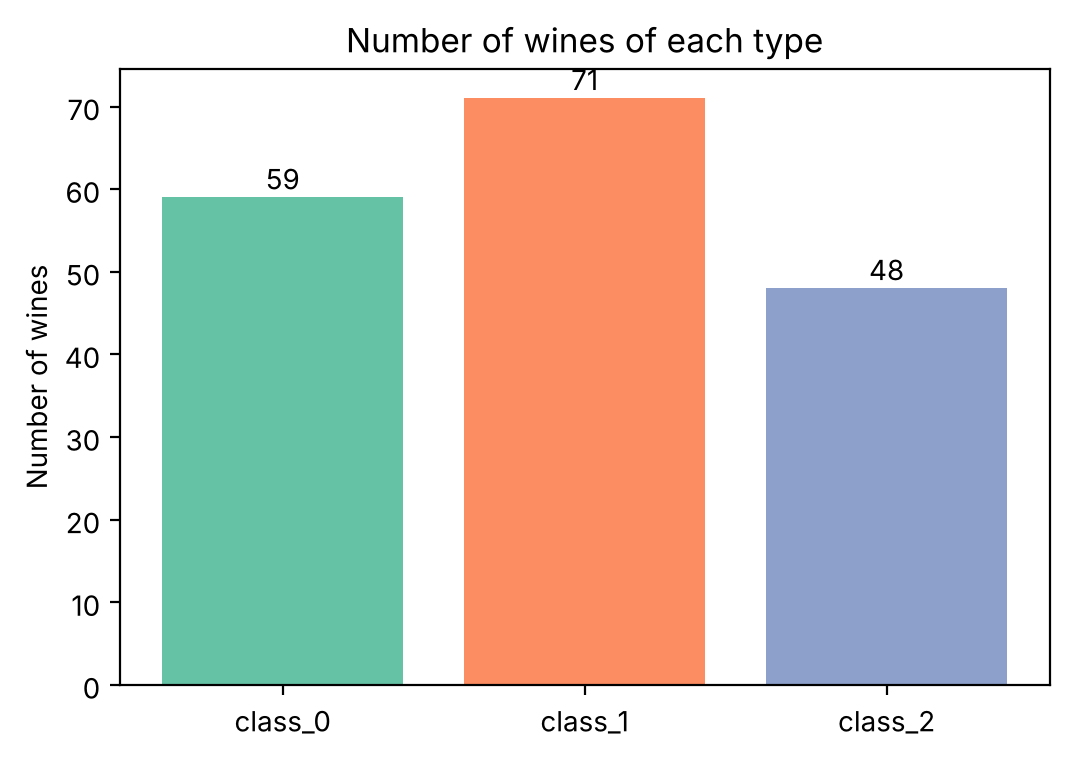

In [3]:
counts = y.value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(class_names, counts.values, color=["#66c2a5", "#fc8d62", "#8da0cb"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 1, str(v), ha="center")
plt.title("Number of wines of each type")
plt.ylabel("Number of wines")
plt.show()

### 3.2 Can two measurements separate the types?
Every dot is one wine, coloured by its type.
If the colours form separate groups, the types are **easy to tell apart**. Here they are quite separate.

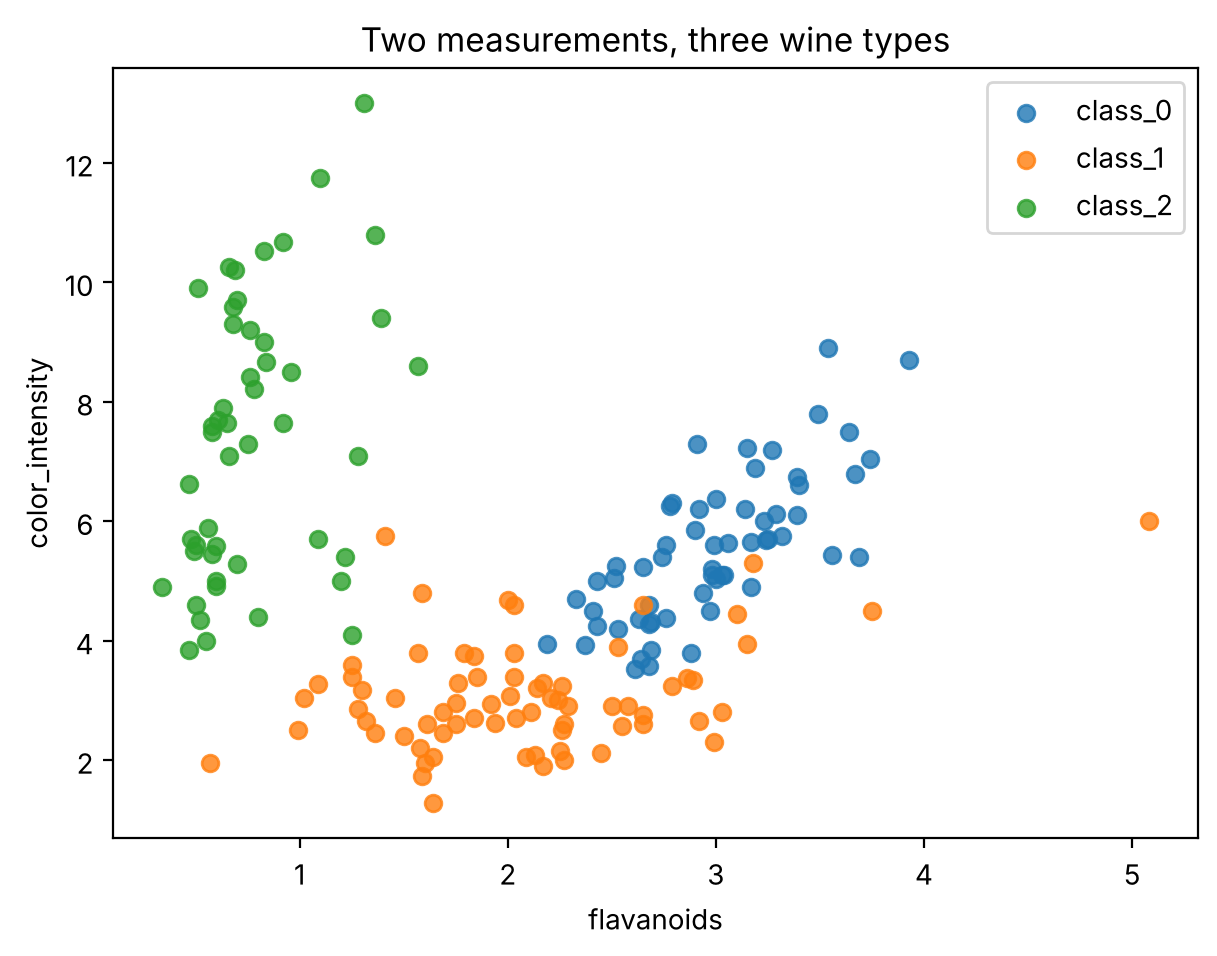

In [4]:
plt.figure(figsize=(7, 5))
for i, name in enumerate(class_names):
    plt.scatter(X.loc[y == i, "flavanoids"], X.loc[y == i, "color_intensity"], label=name, alpha=0.8)
plt.xlabel("flavanoids")
plt.ylabel("color_intensity")
plt.title("Two measurements, three wine types")
plt.legend()
plt.show()

## Step 4: Split the data
A student must not be tested with the same questions he studied.
So we split the wines:
- **Training data (80%)**: the model studies these.
- **Test data (20%)**: hidden. We use it only to check the model, like an exam.

`stratify=y` keeps the same share of each wine type in both parts.
`random_state=42` gives the same split every time.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Wines for training:", len(X_train))
print("Wines for testing :", len(X_test))

Wines for training: 142
Wines for testing : 36


## Step 5: Train the model
Two lines:
1. Create the tree. `max_depth=3` means: ask **at most 3 questions in a row**. This keeps the tree small and easy to read.
2. `fit` = **learn** from the training data.

(No scaling is needed for a Decision Tree. One step less!)

In [6]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
print("Training finished")

Training finished


### Look at the tree it learned
Read it from the top box downward:
- The **first line** is a YES/NO question. **YES goes left, NO goes right.**
- `samples` = how many training wines reached this box.
- `value` = how many of them are type 0, type 1, type 2.
- `class` = the answer the tree gives in this box.
- The box colour shows the type. A **darker colour** means the box is more sure.
- A box at the bottom (no more questions) gives the final answer.

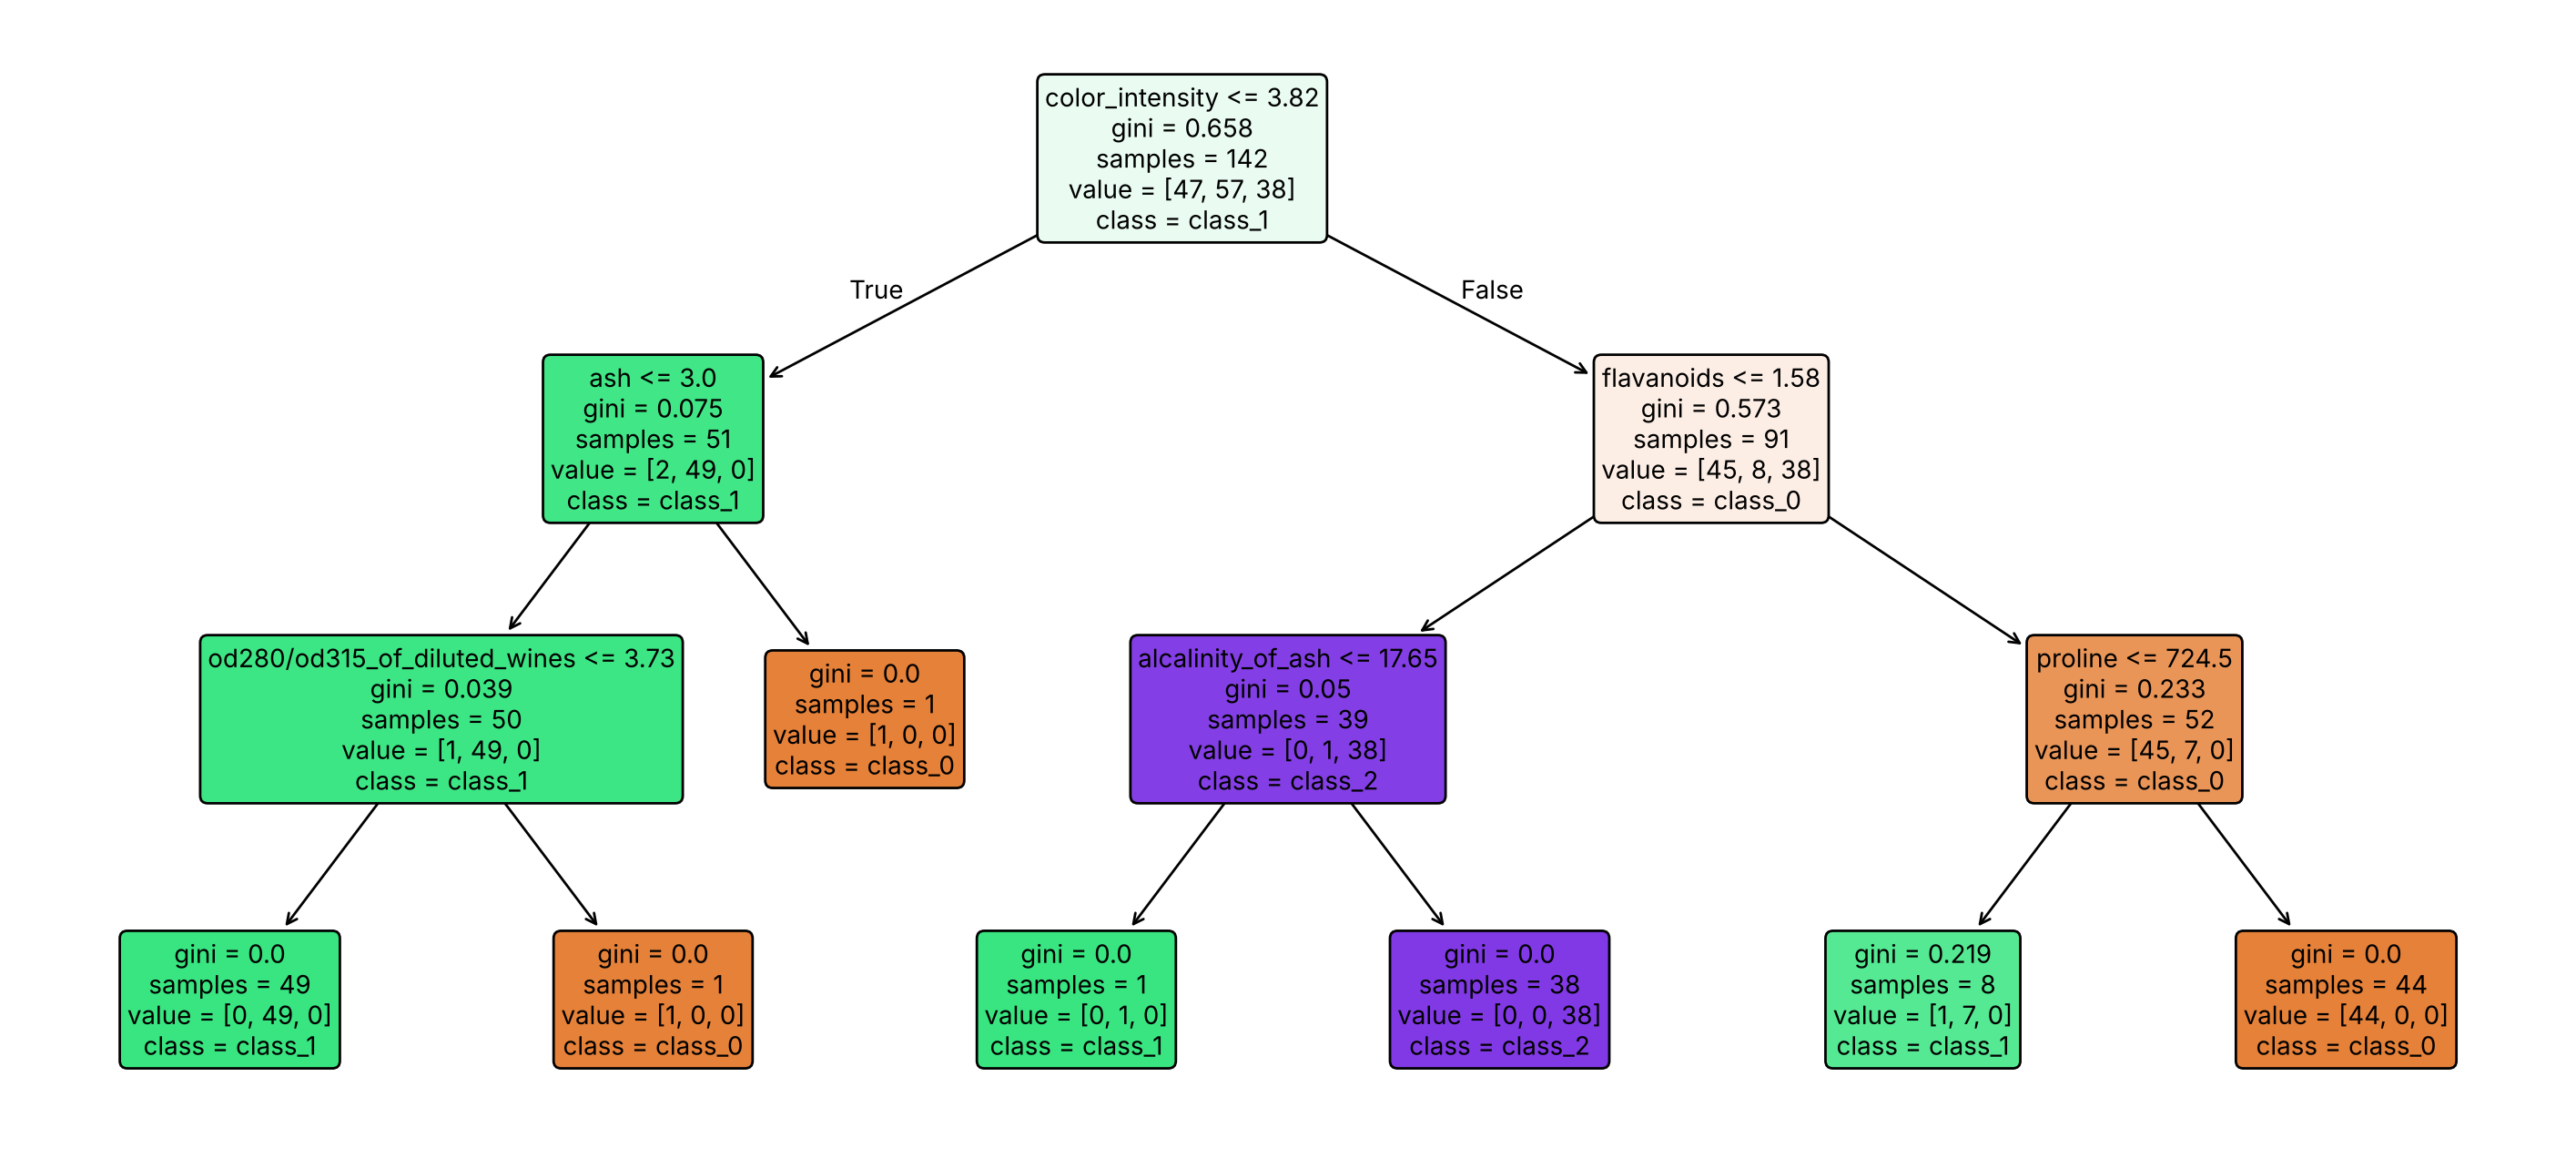

In [7]:
plt.figure(figsize=(18, 8))
plot_tree(model, feature_names=list(X.columns), class_names=class_names, filled=True, rounded=True, fontsize=10)
plt.show()

## Step 6: Make predictions and check them
Now the tree names the type of the **test wines** (wines it has never seen).
We put the real type and the guess side by side.

In [8]:
y_pred = model.predict(X_test)

result = pd.DataFrame({"Real type": y_test.values, "Model guess": y_pred})
result["Correct?"] = np.where(result["Real type"] == result["Model guess"], "Yes", "No")
print("Wrong guesses:", (result["Correct?"] == "No").sum(), "out of", len(result))
result.head(10)

Wrong guesses: 2 out of 36


,Real type,Model guess,Correct?
0,0,0,Yes
1,2,1,No
2,0,0,Yes
3,1,1,Yes
4,1,1,Yes
5,0,0,Yes
6,0,0,Yes
7,1,1,Yes
8,1,1,Yes
9,2,2,Yes


## Step 7: Measure the quality (metrics)

### Confusion matrix (the score sheet)
This table shows **where the model is right and where it gets confused**.
- **Rows** = the real type. **Columns** = the guessed type.
- The **diagonal** (top-left to bottom-right) = **correct** guesses.
- Any number **outside the diagonal** is a mistake. Example: row `class_1`, column `class_2` = a real class_1 wine was guessed as class_2.

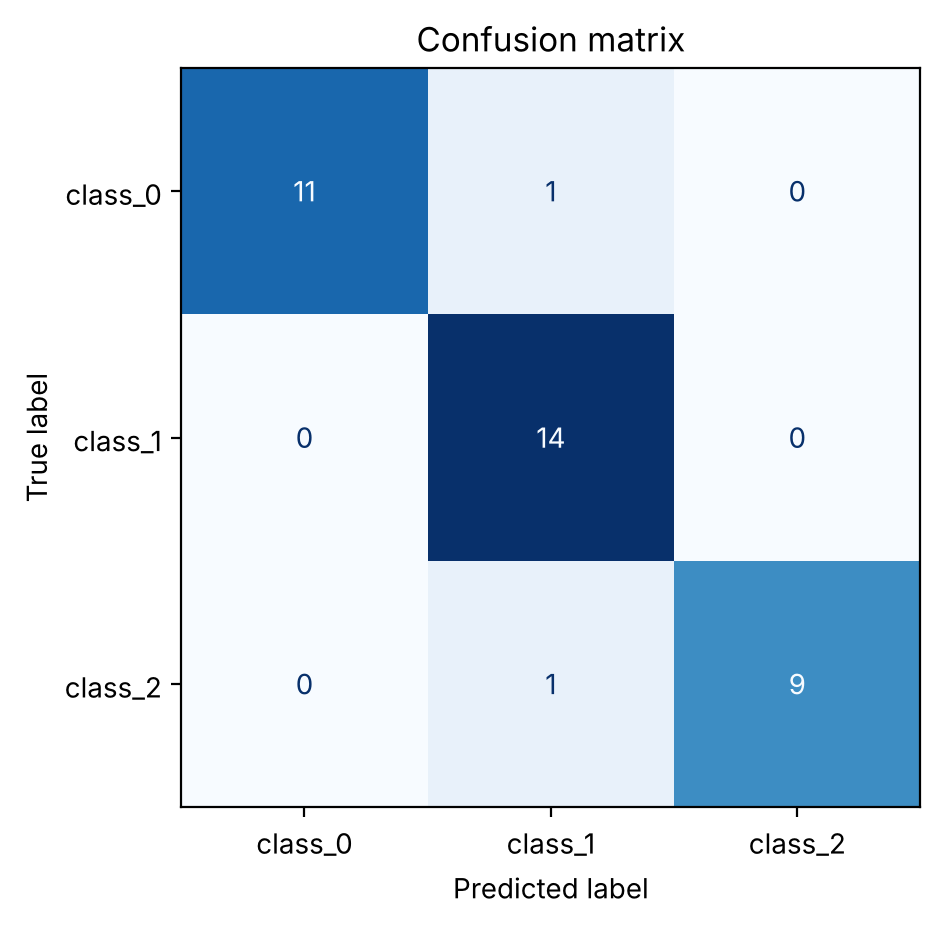

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix")
plt.show()

### The 4 main metrics
**Fruit seller example:** the seller points at 10 fruits and says "mango". 8 are really mangoes. In the whole market there are 16 mangoes.

| Metric | Meaning | Fruit example | Good value |
|---|---|---|---|
| **Accuracy** | Out of all guesses, how many are correct | - | Close to 1 |
| **Precision** | Out of the wines I called "type X", how many really are type X | 8 / 10 = 0.80 | Close to 1 |
| **Recall** | Out of all real type X wines, how many did I find | 8 / 16 = 0.50 | Close to 1 |
| **F1-score** | One number that mixes precision and recall | - | Close to 1 |

For 3 types we calculate precision, recall and F1 for each type and take the **average** (called `macro`).

In [10]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy  = {accuracy:.4f}")
print(f"Precision = {precision:.4f}")
print(f"Recall    = {recall:.4f}")
print(f"F1-score  = {f1:.4f}")

Accuracy  = 0.9444
Precision = 0.9583
Recall    = 0.9389
F1-score  = 0.9457


### Is the model better than a lazy guess?
The laziest guess is to say the **most common type** for every wine. Our model must beat that.

In [11]:
most_common = y_train.value_counts().idxmax()
lazy_accuracy = (y_test == most_common).mean()

print(f"Lazy guess accuracy : {lazy_accuracy:.4f}")
print(f"Our model accuracy  : {accuracy:.4f}")
print("Our model is better!" if accuracy > lazy_accuracy else "Our model is NOT better.")

Lazy guess accuracy : 0.3889
Our model accuracy  : 0.9444
Our model is better!


### Which measurements matter most?
The tree tells how much each measurement helped to separate the wine types. A **longer bar** means a more useful measurement. A measurement with 0 was never used.

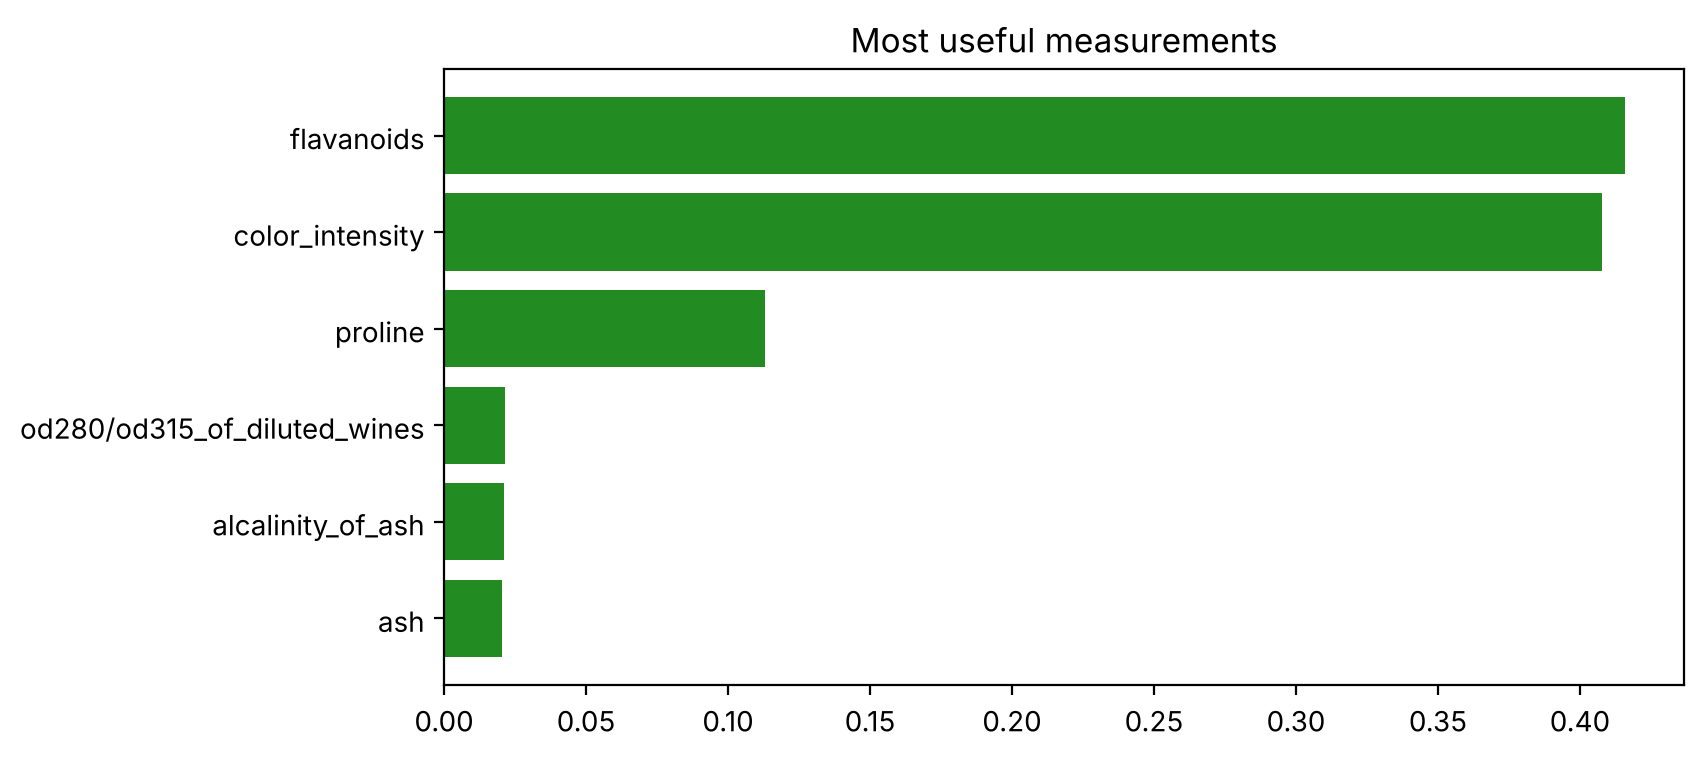

In [12]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()
importance = importance[importance > 0]          # show only the ones the tree used

plt.figure(figsize=(8, 4))
plt.barh(importance.index, importance.values, color="forestgreen")
plt.title("Most useful measurements")
plt.show()

## Conclusion (numbers are filled in automatically)

In [13]:
wrong = int((y_test != y_pred).sum())
print(f"1. The tree guessed the correct type for {len(y_test) - wrong} of {len(y_test)} new wines (accuracy {accuracy * 100:.1f}%).")
print(f"2. The lazy guess gets only {lazy_accuracy * 100:.1f}%, so our model is clearly useful.")
print(f"3. Precision = {precision:.2f}, Recall = {recall:.2f}, F1 = {f1:.2f}.")
print(f"4. The most useful measurement is: {importance.idxmax()}.")

1. The tree guessed the correct type for 34 of 36 new wines (accuracy 94.4%).
2. The lazy guess gets only 38.9%, so our model is clearly useful.
3. Precision = 0.96, Recall = 0.94, F1 = 0.95.
4. The most useful measurement is: flavanoids.


### What we learned
- A **Decision Tree** can learn to name the wine type by asking simple YES/NO questions.
- The wine types are chemically different, so even a small tree works very well. Real-world data is usually harder.
- The test set is small (36 wines), so one mistake changes the accuracy by about 3%.
- Steps we followed: **load, look, split, train, predict, measure**. Almost every Machine Learning project follows the same steps.

### Ideas for later (not needed now)
Try a Random Forest (many trees together), change `max_depth`, or use cross-validation. These are next-level topics.